# 01 — Rice commodity and market selection

## Objective

This notebook narrows the full Myanmar food-price dataset to one monthly rice-price series and selects a market for the first forecasting case study.

**Workflow:** inspect all commodities → select a consistent rice price definition → aggregate prices by market and month → compare market coverage → select Pakokku.

The market-selection criteria are screening rules, not proof that the selected market is universally the best market.

In [3]:
# 1. Environment and configuration

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

## 2. Load and inspect the raw dataset

Start by checking the dataset dimensions, sample records, schema, and date coverage. At this stage, do not filter to rice yet.

In [4]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 61,790
Columns: 16


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [5]:
df_raw.info()
display(df_raw.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 61790 entries, 0 to 61789
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          61790 non-null  str    
 1   admin1        61790 non-null  str    
 2   admin2        61790 non-null  str    
 3   market        61790 non-null  str    
 4   market_id     61790 non-null  int64  
 5   latitude      61790 non-null  float64
 6   longitude     61790 non-null  float64
 7   category      61790 non-null  str    
 8   commodity     61790 non-null  str    
 9   commodity_id  61790 non-null  int64  
 10  unit          61790 non-null  str    
 11  priceflag     61790 non-null  str    
 12  pricetype     61790 non-null  str    
 13  currency      61790 non-null  str    
 14  price         61790 non-null  float64
 15  usdprice      61790 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 7.5 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,61790,224,2025-02-15,883,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin1,61790,15,Rakhine,12953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin2,61790,56,Sittwe,5247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,61790,300,Lashio Market,1227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market_id,61790.0,NaN,NaN,NaN,3540.647338,2716.443522,977.0,1024.0,3293.0,5225.0,12205.0
latitude,61790.0,NaN,NaN,NaN,21.523109,2.834209,11.27,20.18,21.6,23.59,27.34
longitude,61790.0,NaN,NaN,NaN,95.795217,2.099018,92.2,93.6,96.16,97.5,99.61
category,61790,7,vegetables and fruits,12185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,61790,25,Rice (low quality),10231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity_id,61790.0,NaN,NaN,NaN,229.493268,121.512558,51.0,145.0,185.0,324.0,581.0


## 3. Standardize fields and check data quality

Keep `df_raw` unchanged. Create a working copy, standardize column names, and parse fields used in the analysis.

In [6]:
df = df_raw.copy()

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

quality_report = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})
display(quality_report)

print("Exact duplicate rows:", df.duplicated().sum())
print("Invalid dates:", df["date"].isna().sum())
print("Invalid prices:", df["price"].isna().sum())
print("Unique commodities:", df["commodity"].nunique())
print("Unique markets:", df["market_id"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())

,missing_values,missing_percentage
date,0,0.0
admin1,0,0.0
admin2,0,0.0
market,0,0.0
market_id,0,0.0
latitude,0,0.0
longitude,0,0.0
category,0,0.0
commodity,0,0.0
commodity_id,0,0.0


Exact duplicate rows: 0
Invalid dates: 0
Invalid prices: 0
Unique commodities: 25
Unique markets: 300
Date range: 2008-01-15 00:00:00 to 2026-09-15 00:00:00


## 4. Compare the commodities

The first selection question is: **which commodities are represented in the dataset, and how much data is available for each?**

Record counts are a useful first screen, but they do not by themselves determine which commodity is most important or easiest to forecast.

,records,markets,first_date,last_date
commodity,,,,
Rice (low quality),10231,298,2008-01-15,2026-09-15
Salt,9702,294,2008-01-15,2026-09-15
Pulses,8015,276,2012-01-15,2026-09-15
Oil (palm),7565,274,2008-01-15,2026-09-15
Onions (local),6137,252,2020-07-15,2026-09-15
Eggs (local),6130,250,2020-07-15,2026-09-15
Tomatoes (local),5020,243,2020-07-15,2026-09-15
Fuel (diesel),1747,41,2014-01-15,2020-03-15
"Wage (non-qualified labour, non-agricultural)",1703,41,2014-01-15,2020-03-15


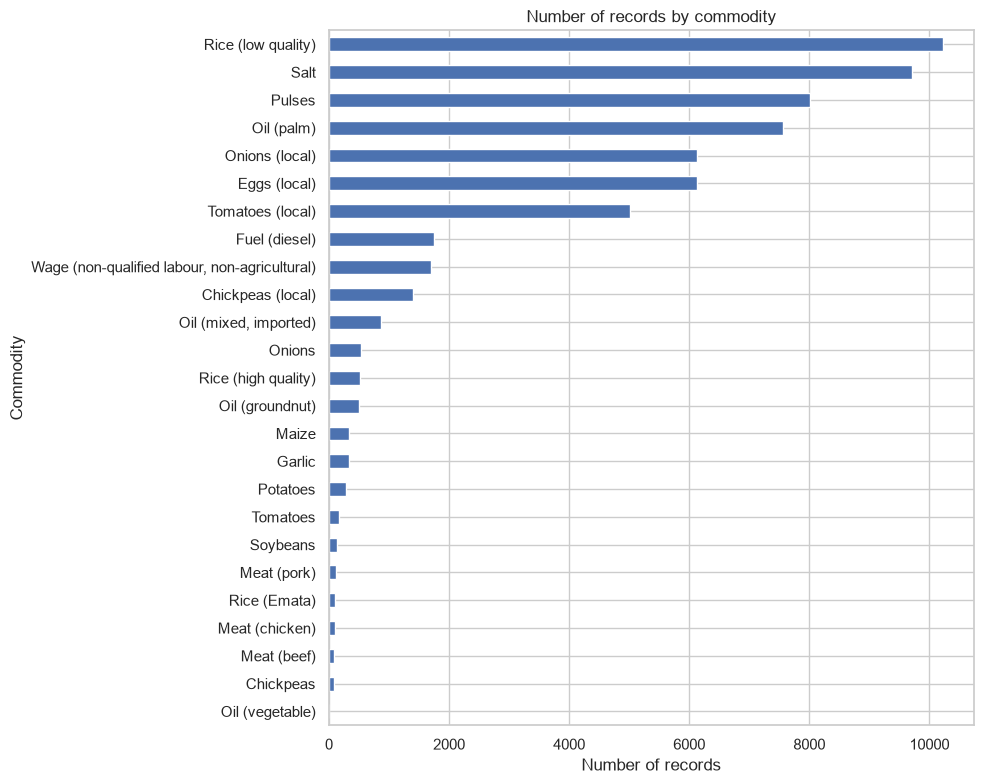

In [7]:
commodity_summary = (
    df.groupby("commodity")
    .agg(
        records=("commodity", "size"),
        markets=("market_id", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .sort_values("records", ascending=False)
)

display(commodity_summary)

ax = commodity_summary["records"].sort_values().plot(
    kind="barh", figsize=(10, 8),
    title="Number of records by commodity"
)
ax.set_xlabel("Number of records")
ax.set_ylabel("Commodity")
plt.tight_layout()
plt.show()

### Commodity choice

For this project, the selected target is **Rice (low quality)**. The price definition is narrowed to **retail prices in MMK per KG** so that the series has a consistent commodity, unit, price type, and currency.

This is a project-scope decision. It should not be interpreted as a claim that low-quality rice is the only useful commodity in the source dataset.

In [8]:
# 5. Apply the selected rice price definition

TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"

rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].copy()

# A date and numeric price are required for monthly aggregation.
rice_df = rice_df.dropna(subset=["date", "price"])

print(f"Selected rice records: {len(rice_df):,}")
print(f"Selected markets: {rice_df['market_id'].nunique()}")
print("Selected date range:", rice_df["date"].min(), "to", rice_df["date"].max())
display(rice_df.head())

Selected rice records: 10,231
Selected markets: 298
Selected date range: 2008-01-15 00:00:00 to 2026-09-15 00:00:00


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
7,2008-01-15,Magway,Magway,Magway,997,20.15,94.92,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,604.17,0.62
10,2008-01-15,Magway,Magway,Yenanchaung,1023,20.46,94.87,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,900.00,0.93
12,2008-01-15,Magway,Pakokku,Pakhangyi,1011,21.54,95.20,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,541.67,0.56
14,2008-01-15,Rakhine,Maungdaw,Alel Than Kyaw,977,20.68,92.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,460.00,0.47


## 6. Aggregate observations to monthly market prices

The source can contain more than one observation for a market within a month. For this first analysis, calculate the **mean observed price** for each market-month and retain the number of source observations contributing to that mean.

In [9]:
rice_df["month"] = rice_df["date"].dt.to_period("M")

monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

duplicate_market_months = monthly_rice.duplicated(
    subset=["market_id", "month"]
).sum()
print("Duplicate market-month pairs:", duplicate_market_months)
assert duplicate_market_months == 0
display(monthly_rice.head())

Duplicate market-month pairs: 0


,market_id,market,month,monthly_price,observation_count
0,977,Alel Than Kyaw,2008-01,460.0,1
1,977,Alel Than Kyaw,2008-02,450.0,1
2,977,Alel Than Kyaw,2008-03,440.0,1
3,977,Alel Than Kyaw,2008-04,480.0,1
4,977,Alel Than Kyaw,2008-05,480.0,1


## 7. Measure each market's historical coverage

For each market, compare the number of observed months with the number of calendar months between its first and last observations.

**Important:** this coverage percentage measures gaps *inside each market's observed date span*. It does not count months before the first observation or after the last observation.

In [10]:
def longest_internal_gap(observed_months):
    """Return the longest run of missing months inside a market's date span."""
    observed_months = pd.PeriodIndex(observed_months).unique().sort_values()
    if len(observed_months) == 0:
        return 0

    full_months = pd.period_range(
        start=observed_months.min(),
        end=observed_months.max(),
        freq="M"
    )
    missing_flags = ~full_months.isin(observed_months)

    longest_run = 0
    current_run = 0
    for is_missing in missing_flags:
        if is_missing:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 0

    return longest_run

market_coverage = (
    monthly_rice.groupby(["market_id", "market"])
    .agg(
        first_month=("month", "min"),
        last_month=("month", "max"),
        observed_months=("month", "nunique")
    )
    .reset_index()
)

market_coverage["span_months"] = (
    market_coverage["last_month"].map(lambda month: month.ordinal)
    - market_coverage["first_month"].map(lambda month: month.ordinal)
    + 1
)
market_coverage["missing_internal_months"] = (
    market_coverage["span_months"] - market_coverage["observed_months"]
)
market_coverage["coverage_pct"] = (
    market_coverage["observed_months"]
    / market_coverage["span_months"] * 100
).round(2)

max_gap_by_market = (
    monthly_rice.groupby("market_id")["month"]
    .apply(longest_internal_gap)
    .rename("max_consecutive_gap")
)
market_coverage = market_coverage.merge(
    max_gap_by_market, on="market_id", how="left"
)

market_coverage = market_coverage.sort_values(
    ["observed_months", "coverage_pct"],
    ascending=[False, False]
).reset_index(drop=True)

display(market_coverage.head(15))

,market_id,market,first_month,last_month,observed_months,span_months,missing_internal_months,coverage_pct,max_consecutive_gap
0,1658,Lashio Market,2008-01,2026-09,202,225,23,89.78,3
1,978,Buthidaung,2008-01,2026-08,162,224,62,72.32,32
2,1664,Pakokku Myo Ma Market,2014-01,2026-09,146,153,7,95.42,3
3,983,Hakha Myoma Market,2010-06,2025-03,139,178,39,78.09,20
4,997,Magway,2008-01,2020-03,135,147,12,91.84,3
5,1661,Kutkai,2014-01,2026-09,130,153,23,84.97,12
6,1370,Tedim Municipal Market,2012-01,2025-02,124,158,34,78.48,25
7,1657,Shwegu,2014-01,2025-02,123,134,11,91.79,7
8,1014,Rathedaung,2008-01,2026-09,123,225,102,54.67,26
9,1020,Tonzang,2010-06,2025-02,121,177,56,68.36,25


## 8. Screen markets for a first forecasting case study

Use two initial screening rules from the original analysis:

1. At least **36 observed monthly values**.
2. The market's last observation is in the dataset's latest calendar year.

This is a broad recency screen: it does not require the market to have a value in the latest month. Review `last_month` before final selection.

In [11]:
MIN_OBSERVED_MONTHS = 36
LATEST_DATA_YEAR = monthly_rice["month"].max().year

candidate_markets = market_coverage[
    (market_coverage["observed_months"] >= MIN_OBSERVED_MONTHS)
    & (market_coverage["last_month"].dt.year == LATEST_DATA_YEAR)
].copy()

print("Latest year represented in rice data:", LATEST_DATA_YEAR)
print("Markets passing initial screen:", len(candidate_markets))

display(
    candidate_markets
    .sort_values(
        ["coverage_pct", "observed_months"],
        ascending=[False, False]
    )
    .head(15)
)

Latest year represented in rice data: 2026
Markets passing initial screen: 57


,market_id,market,first_month,last_month,observed_months,span_months,missing_internal_months,coverage_pct,max_consecutive_gap
25,3280,Hlaing Bwe Myo Ma market,2020-04,2026-09,77,78,1,98.72,1
26,3302,Kanthar,2020-04,2026-09,77,78,1,98.72,1
27,3308,Minbu Myo Ma Market,2020-04,2026-09,77,78,1,98.72,1
76,8028,KalawMyoma,2022-09,2026-09,48,49,1,97.96,1
116,9094,Salin Myoma,2023-09,2026-09,36,37,1,97.30,1
41,6087,YaeNiMyaung,2021-07,2026-09,61,63,2,96.83,1
42,6089,Meegwet,2021-07,2026-09,61,63,2,96.83,1
43,6090,YwarMa,2021-07,2026-09,61,63,2,96.83,1
54,6377,ManiSithu,2021-10,2026-09,58,60,2,96.67,1
30,3297,Lahe,2020-04,2026-09,75,78,3,96.15,1


## 9. Compare Lashio and Pakokku

The original market-selection work compared markets with long histories and recent observations. Lashio has more monthly records, while Pakokku has a higher proportion of observed months within its own date span. This comparison makes the trade-off explicit rather than ranking markets by record count alone.

In [12]:
MARKETS_TO_COMPARE = [1658, 1664]  # Lashio and Pakokku

market_comparison = (
    market_coverage[market_coverage["market_id"].isin(MARKETS_TO_COMPARE)]
    .sort_values("coverage_pct", ascending=False)
    .reset_index(drop=True)
)
display(market_comparison)

,market_id,market,first_month,last_month,observed_months,span_months,missing_internal_months,coverage_pct,max_consecutive_gap
0,1664,Pakokku Myo Ma Market,2014-01,2026-09,146,153,7,95.42,3
1,1658,Lashio Market,2008-01,2026-09,202,225,23,89.78,3


## 10. Market-selection decision

**Selected market: Pakokku Myo Ma Market (Market ID: 1664).**

The current notebook results show:

- Pakokku: 146 observed months across a 153-month span (January 2014–September 2026), 7 internal missing months, 95.42% coverage, and a longest gap of 3 consecutive months.
- Lashio: 202 observed months across a 225-month span (January 2008–September 2026), 23 internal missing months, 89.78% coverage, and a longest gap of 3 consecutive months.

Lashio offers a longer history and more observations. Pakokku offers a shorter but more complete series, with more than 12 years of monthly coverage. We select Pakokku for the first case study because continuity is important for the initial forecasting exercise. This is a practical project choice, not a claim that Pakokku is the best market for every possible analysis.

In [13]:
PAKOKKU_ID = 1664

pakokku_summary = market_coverage.loc[
    market_coverage["market_id"] == PAKOKKU_ID
]

if pakokku_summary.empty:
    raise ValueError(f"Pakokku market ID {PAKOKKU_ID} was not found.")

display(pakokku_summary)

,market_id,market,first_month,last_month,observed_months,span_months,missing_internal_months,coverage_pct,max_consecutive_gap
2,1664,Pakokku Myo Ma Market,2014-01,2026-09,146,153,7,95.42,3


## Handoff to Notebook 02

The next notebook focuses only on Pakokku's monthly rice-price series. It will:

1. Build a complete month index from Pakokku's first through last observed month.
2. Identify and summarize its internal missing periods.
3. Use other markets only as supporting context for those gaps.
4. Decide how to preserve missing values for the first forecasting baseline.

No imputation is performed in this notebook.